# Misión 4 · Del dato al proceso
Python toma el control · AI Customer Intelligence

Trabaja desde la carpeta `proyecto`. Alterna conductor y revisor en cada reto.
Reinicia el kernel y ejecuta todas las celdas antes de entregar.
Los datos de este kit son sintéticos; no entrenamos un modelo en esta misión.

In [1]:
from pathlib import Path
import pandas as pd
BASE = Path.cwd()
assert (BASE / 'datos').exists(), 'Abre Jupyter desde la carpeta proyecto'

## Reto 1 · El inspector de clientes (25 minutos)
Completa `validaciones.py`. Devuelve todos los errores y conserva el diccionario original.
1. id_cliente existe y no es None.
2. antiguedad_meses no es negativa.
3. abandono pertenece a 0 o 1.
En este primer reto los dos últimos campos existen y son enteros.
Recorre la lista con un bucle y cuenta clientes con errores (no mensajes).
Mueve la función a un módulo e impórtala; reinicia el kernel al editarlo.

In [2]:
from validaciones import validar_cliente
clientes = [
    {'id_cliente': 101, 'antiguedad_meses': 12, 'abandono': 0},
    {'id_cliente': 102, 'antiguedad_meses': -3, 'abandono': 2},
    {'id_cliente': 103, 'antiguedad_meses': 8, 'abandono': 1},
]
# TODO: imprime errores y cuenta clientes con errores.

df_clientes = pd.DataFrame(clientes)

df_clientes["errores"] = df_clientes.apply(lambda fila: validar_cliente(fila), axis=1)

print(df_clientes[["id_cliente", "errores"]])

n_con_errores = (df_clientes["errores"].str.len() > 0).sum()
print("Clientes con errores:", n_con_errores)

   id_cliente                                   errores
0         101                                        []
1         102  [antiguedad invalida, abandono invalido]
2         103                                        []
Clientes con errores: 1


## Reto 2 · Abre el puente (30 minutos)
Copia `.env.example` como `.env`; configura tus credenciales.
Conecta con `mysql.connector`, cuenta clientes y recupera los cinco primeros.
Compara con Workbench. Cierra recursos incluso cuando falle una consulta.
Prueba un DB_NAME inexistente y documenta el diagnóstico. Restaura `.env` y reinicia
el kernel: `load_dotenv` no sustituye por defecto variables ya cargadas.
Nunca incluyas credenciales en capturas ni en la entrega.

In [3]:
# TODO: leer configuraci?n, conectar y consultar.
# SELECT COUNT(*) FROM clientes;
# SELECT id_cliente, nombre, antiguedad_meses
# FROM clientes ORDER BY id_cliente LIMIT 5;

import os
from dotenv import load_dotenv
import mysql.connector
from mysql.connector import Error

# 1. Leer environment; preferir .env de proyecto y luego el de la ra?z.
env_path = next((path for path in (BASE / ".env", BASE.parent / ".env") if path.is_file()), None)
if env_path is None:
    raise FileNotFoundError("No se encuentra .env en proyecto ni en la carpeta ra?z del workspace.")
load_dotenv(env_path, override=True)
config = {
    "host": os.getenv("DB_HOST"),
    "port": int(os.getenv("DB_PORT", 3306)),
    "user": os.getenv("DB_USER"),
    "password": os.getenv("DB_PASSWORD"),
    "database": os.getenv("DB_NAME"),
}

faltan = [nombre for nombre, valor in config.items() if nombre != "port" and not valor]
if faltan:
    raise ValueError(f"Faltan valores de configuraci?n en .env: {', '.join(faltan)}")

conexion = None
cursor = None
try:
    # 2. Conectar con mysql
    conexion = mysql.connector.connect(**config)
    cursor = conexion.cursor()

    # 3. Realizar consulta con mysql
    cursor.execute("SELECT COUNT(*) FROM clientes")
    total = cursor.fetchone()[0]
    print("Total clientes:", total)

    cursor.execute("""
        SELECT id_cliente, nombre, antiguedad_meses
        FROM clientes
        ORDER BY id_cliente
        LIMIT 5
    """)

    clientes_limitados = cursor.fetchall()
    for fila in clientes_limitados:
        print(fila)

except Error as e:
    print(f"Error MySQL [{e.errno}]: {e.msg}")
    raise

finally:
    # 4. Cerrar recursos SIEMPRE, tambi?n si algo fall?
    if cursor is not None:
        cursor.close()
    if conexion is not None and conexion.is_connected():
        conexion.close()
    print("Se ha cerrado la conexion")

Total clientes: 12
(101, 'Cliente 101', 12)
(102, 'Cliente 102', 4)
(103, 'Cliente 103', 24)
(104, 'Cliente 104', 2)
(105, 'Cliente 105', 36)
Se ha cerrado la conexion


## Reto 3 · Recupera el dataset (30 minutos)
Escribe tu SQL en `consulta_dataset.sql`. Debe preservar clientes sin operaciones.
Recupera todas las filas y cursor.description; construye el DataFrame con los nombres SQL.
Revisa shape, info e isna. Comprueba ids únicos y cobertura frente a la tabla clientes.
Antes de agregar, detecta `importe IS NULL` en operaciones: no equivale a cero.
El CSV tendrá exactamente las seis columnas acordadas.

In [4]:
# Ejecutar la consulta guardada y crear el DataFrame con los nombres SQL.
conexion = None
cursor = None

try:
    conexion = mysql.connector.connect(**config)
    cursor = conexion.cursor()

    cursor.execute("SELECT COUNT(*) FROM operaciones WHERE importe IS NULL")
    n_importes_nulos = cursor.fetchone()[0]
    if n_importes_nulos:
        raise ValueError(f"Hay {n_importes_nulos} operaciones con importe NULL; revisa el origen antes de agregar.")

    consulta = (BASE / "consulta_dataset.sql").read_text(encoding="utf-8")
    cursor.execute(consulta)
    nombres_columnas = [columna[0] for columna in cursor.description]
    resultado_query_1 = cursor.fetchall()
    df_resultado_query_1 = pd.DataFrame(resultado_query_1, columns=nombres_columnas)

    cursor.execute("SELECT id_cliente FROM clientes")
    ids_esperados = {fila[0] for fila in cursor.fetchall()}
    ids_presentes = set(df_resultado_query_1["id_cliente"].dropna())
    ids_faltantes = ids_esperados - ids_presentes

    print(df_resultado_query_1)
    print("Shape:", df_resultado_query_1.shape)
    df_resultado_query_1.info()
    print("Valores ausentes por columna:")
    print(df_resultado_query_1.isna().sum())
    print("IDs duplicados:", df_resultado_query_1["id_cliente"].duplicated().sum())
    print("IDs faltantes:", sorted(ids_faltantes))

finally:
    if cursor is not None:
        cursor.close()
    if conexion is not None and conexion.is_connected():
        conexion.close()
    print("Se ha cerrado la conexion")

    id_cliente  antiguedad_meses  num_operaciones gasto_total ticket_medio  \
0          101                12                3      180.00        60.00   
1          102                 4                1       30.00        30.00   
2          103                24                2      240.00       120.00   
3          104                 2                0        0.00         0.00   
4          105                36                4      400.00       100.00   
5          106                 8                2       60.00        30.00   
6          107                18                0        0.00         0.00   
7          108                 6                1       45.00        45.00   
8          109                30                3      270.00        90.00   
9          110                10                2      100.00        50.00   
10         111                15                1       80.00        80.00   
11         112                 3                0        0.00   

### Respaldo si MySQL bloquea la sesión
Puedes practicar pandas con el siguiente CSV. Identifica el origen en tus evidencias.
Este respaldo no acredita el reto de conexión a MySQL.

In [5]:
df_referencia = pd.read_csv(BASE / 'datos/dataset_referencia.csv')
df_referencia.head()

,id_cliente,antiguedad_meses,num_operaciones,gasto_total,ticket_medio,abandono
0,101,12,3,180,60,0
1,102,4,1,30,30,1
2,103,24,2,240,120,0
3,104,2,0,0,0,1
4,105,36,4,400,100,0


## Reto 4 · Control de calidad (30 minutos)
Trabaja sobre una copia. Completa `validar_dataset` y registra campo, regla, filas y acción.
Revisa estructura, faltantes, duplicados, tipos numéricos finitos, enteros donde procede,
rangos y abandono 0/1. Comprueba cobertura si conoces los ids esperados.
No elimines duplicados ni rellenes faltantes con cero sin evidencia.
La copia con incidencias debe bloquear la exportación; el informe debe guardarse.

In [6]:
import json
from validaciones import validar_dataset 
df_prueba = pd.read_csv(BASE / 'datos/dataset_con_incidencias.csv')
# TODO: diagnóstico antes/después y validación.
copia = df_prueba.copy()
print("copia shape ",copia.shape)
copia.info()

# faltantes por columna
print("faltantes por columna: \n",copia.isna().sum())
# id repetidos 
print("id repetidos : \n",copia[copia['id_cliente'].duplicated(keep=False)])
# lo logico en caso de que este no sea el df correcto
# se guarde un cv o un df del reto 3
ids_esperados = df_referencia['id_cliente'].tolist()
informe = validar_dataset(copia, ids_esperados)

with open(BASE / 'informe_prueba.json', 'w', encoding='utf-8') as f:
    json.dump(informe, f, indent=2, ensure_ascii=False)

print('Válido:', informe['valido']) 
for inc in informe['incidencias']:
    print(inc)

# validar que de true en in df correcto
informe_valido = validar_dataset(df_referencia, ids_esperados)
print('Válido:', informe_valido['valido']) 
for inc in informe_valido['incidencias']:
    print(inc)


copia shape  (13, 6)
<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_cliente        12 non-null     float64
 1   antiguedad_meses  13 non-null     float64
 2   num_operaciones   13 non-null     float64
 3   gasto_total       12 non-null     str    
 4   ticket_medio      13 non-null     int64  
 5   abandono          13 non-null     int64  
dtypes: float64(3), int64(2), str(1)
memory usage: 787.0 bytes
faltantes por columna: 
 id_cliente          1
antiguedad_meses    0
num_operaciones     0
gasto_total         1
ticket_medio        0
abandono            0
dtype: int64
id repetidos : 
     id_cliente  antiguedad_meses  num_operaciones gasto_total  ticket_medio  \
0        101.0              12.0              3.0         180            60   
12       101.0              12.0              3.0         180            60   

    abandono  
0        

Válido: True


## Microreto · Pandas y matplotlib (20 minutos)
Sobre los datos válidos: selecciona columnas, filtra gasto_total > 100 y ordena de mayor a menor.
Añade sin_operaciones en una copia de análisis; conserva el esquema de seis columnas al exportar.
Resume gasto por abandono con count, mean y median. Representa gasto medio, con título,
ejes y unidad (euros en la demo). Si falta un grupo, dilo: su media no es cero.
Escribe una observación y una limitación: la diferencia no demuestra causalidad.

   id_cliente  gasto_total
4         105          400
8         109          270
2         103          240
0         101          180
          count        mean  median
abandono                           
0             6  195.000000   210.0
1             6   39.166667    37.5


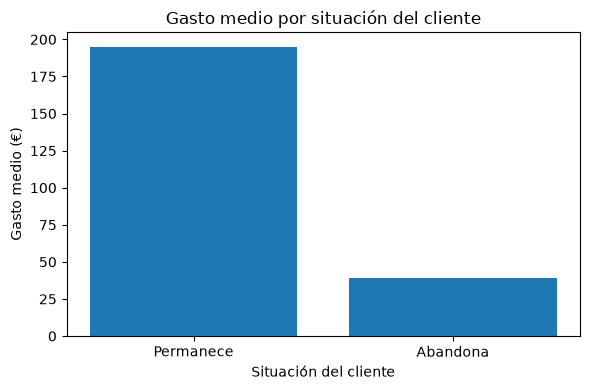

In [7]:
import matplotlib.pyplot as plt
# TODO: selección, filtro, columna derivada, resumen y gráfico.

df = df_referencia      # o el df de MySQL

seleccion = df.loc[df['gasto_total'] > 100, ['id_cliente', 'gasto_total']]
seleccion = seleccion.sort_values('gasto_total', ascending=False)
print(seleccion)

analisis = df.copy()
analisis['sin_operaciones'] = analisis['num_operaciones'].eq(0)

resumen = analisis.groupby('abandono')['gasto_total'].agg(['count', 'mean', 'median'])
print(resumen)

for grupo in [0, 1]:
    if grupo not in resumen.index:
        print(f'Aviso: no hay clientes con abandono={grupo}; su media no es 0, es desconocida')

medias = resumen['mean'].rename(index={0: 'Permanece', 1: 'Abandona'})

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(medias.index, medias.values)
ax.set(title='Gasto medio por situación del cliente',
       xlabel='Situación del cliente',
       ylabel='Gasto medio (€)')
fig.tight_layout()
plt.show()

## Reto final · Una ejecución, un dataset (30 minutos)
Completa `pipeline.py`: extraer, validar, guardar informe, exportar y generar gráfico.
Una carpeta por ejecución evita confundir resultados antiguos con una ejecución fallida.
CSV/PNG solo si la validación pasa; informe también si falla.
Ejecuta desde una terminal nueva, sin depender de variables del notebook.

## Evidencias y defensa (15 minutos)
Completa `../Plantilla_evidencias.md` y el README. Entrega notebook, módulos, SQL,
CSV, informe JSON, gráfico, `.env.example`, `.gitignore` y requirements.
Excluye `.env` y claves. Cada integrante explica una decisión y modifica una regla.
Declara la ayuda de IA recibida y cómo verificaste su resultado.

In [8]:
from pipeline import main as ejecutar_pipeline

ruta_resultados = ejecutar_pipeline()
print("Resultados de esta ejecuci?n:", ruta_resultados)
print("Si el informe indica valido=False, no se crean CSV ni gr?fico.")

Informe guardado en: C:\Users\sarah\OneDrive\Desktop\Master_IA\MODULO2\Mision4\modulo2-mision4-main\proyecto\salidas\ejecucion_20261027_183610_262153\informe.json


Resultados de esta ejecuci?n: C:\Users\sarah\OneDrive\Desktop\Master_IA\MODULO2\Mision4\modulo2-mision4-main\proyecto\salidas\ejecucion_20261027_183610_262153
Si el informe indica valido=False, no se crean CSV ni gr?fico.
